# Chapitre 4 - Exercices 4.7 à 4.10

Ce notebook traite les exercices 4.7 à 4.10, centrés sur les flux de données :

- **4.7** : modèle de Markov des champs perdus pendant un déploiement progressif
  (calcul et simulation) ;
- **4.8** : dimensionner le stockage et le transport du schéma de l'écrivain (calcul) ;
- **4.9** : quels changements d'API sont sûrs, selon l'ordre de déploiement ?
  (raisonnement et vérification) ;
- **4.10** : délais d'expiration, relances et doublons d'un appel distant (calcul et
  simulation).

In [1]:
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)
rng = np.random.default_rng(0)

## Exercice 4.7 : combien de champs perdus pendant un déploiement ?

**Énoncé.** On reprend la simulation du cours 2 (`E.simulate_rolling_upgrade`) : 2 000
enregistrements, 10 nœuds, 60 mises à jour par pas de temps, chacune sur un enregistrement
et par un nœud tirés au hasard. Le nœud $k$ ($k = 0..9$) passe en v2 au pas $20 + 10k$. Une
mise à jour par un nœud v2 permet d'ajouter une photo si l'enregistrement n'en a jamais
eu ; une mise à jour par un nœud v1 efface la photo (il ne préserve pas les champs
inconnus).

1. Modéliser **un** enregistrement par une chaîne de Markov à trois états (sans photo,
   avec photo, photo perdue) et calculer exactement la fraction d'enregistrements dont la
   photo est perdue à la fin. Comparer à la simulation.
2. Montrer que, pour une part de nœuds v2 qui croît linéairement de 0 à 1 sur une durée
   $D$, un enregistrement qui reçoit sa photo à l'instant $\tau$ la conserve avec
   probabilité $\exp(-\lambda (D-\tau)^2 / (2D))$, où $\lambda$ est le taux de mises à jour
   par enregistrement.
3. Comment la perte évolue-t-elle si le déploiement dure deux ou quatre fois plus
   longtemps ? Qu'en conclure ?

**Rappels.** Un ancien code qui décode dans son modèle d'objet et réécrit efface les
champs inconnus (cours 1, section 1 ; cours 2, section 4). Pendant le déploiement, la part
$s(t)$ de nœuds v2 croît.

**Solution.**

*1.* À chaque mise à jour, l'enregistrement est visé avec probabilité $q = 1/2000$ ; le
nœud est v2 avec probabilité $s(t)$. Transitions : sans photo -> avec photo avec
probabilité $q\,s(t)$ ; avec photo -> perdue avec probabilité $q\,(1 - s(t))$ ; « perdue »
est absorbant (l'utilisateur ne la remet pas). On propage le vecteur de probabilités
mise à jour après mise à jour (12 000 étapes).

*2.* Les mises à jour par des nœuds v1 forment un processus de Poisson d'intensité
$\lambda (1 - s(t))$ ; la photo survit s'il n'y en a aucune entre $\tau$ et $D$ :
$\exp\left(-\lambda \int_\tau^D (1 - t/D)\,dt\right) = \exp\left(-\lambda (D-\tau)^2 / (2D)\right)$.

*3.* L'exposant est proportionnel à $\lambda D$ : un déploiement plus long laisse plus de
mises à jour par des nœuds v1 après l'ajout de la photo, donc plus de pertes.

In [2]:
def markov_pertes(n_rec=2000, n_nodes=10, debut=20, tous=10, par_pas=60, duree=200):
    q = 1 / n_rec
    sans, photo, perdu = 1.0, 0.0, 0.0
    for t in range(duree):
        s = sum(t >= debut + k * tous for k in range(n_nodes)) / n_nodes
        for _ in range(par_pas):
            a = q * s * sans                  # sans -> photo
            b = q * (1 - s) * photo           # photo -> perdu
            sans, photo, perdu = sans - a, photo + a - b, perdu + b
    return photo, perdu

photo, perdu = markov_pertes()
sims = [E.simulate_rolling_upgrade(seed=k).iloc[-1] for k in range(20)]
print(f"Markov : photo présente {photo:.3f}, perdue {perdu:.3f} ; part des photos ajoutées qui sont perdues {perdu / (photo + perdu):.3f}")
print(f"simulation (20 graines) : photo présente {np.mean([r.avec_photo for r in sims]):.3f}, "
      f"perdues {np.mean([r.photos_perdues for r in sims]) / 2000:.3f}")

Markov : photo présente 0.772, perdue 0.210 ; part des photos ajoutées qui sont perdues 0.214
simulation (20 graines) : photo présente 0.771, perdues 0.212


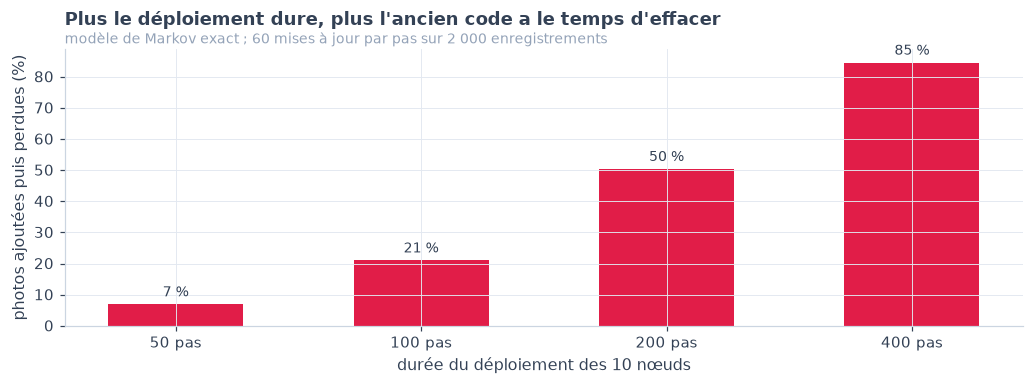

In [3]:
tous = [5, 10, 20, 40]
res = [markov_pertes(tous=k, duree=40 + 10 * k + 200) for k in tous]
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.bar([f"{10 * k} pas" for k in tous], [100 * p / (p + c) for c, p in res], color=ROSE, width=0.55)
annotate_bars(ax, "{:.0f} %")
ax.set_xlabel("durée du déploiement des 10 nœuds"); ax.set_ylabel("photos ajoutées puis perdues (%)")
ax.set_title("Plus le déploiement dure, plus l'ancien code a le temps d'effacer")
subtitle(ax, "modèle de Markov exact ; 60 mises à jour par pas sur 2 000 enregistrements")
plt.tight_layout(); plt.show()

Le modèle exact (environ 21 % des photos ajoutées sont perdues, 77 % des enregistrements
ont une photo à la fin) coïncide avec la moyenne des simulations. Allonger le déploiement aggrave fortement
la perte : un déploiement progressif prudent, étalé sur des jours, est justement celui
qui laisse le plus de temps à l'ancien code pour effacer les champs nouveaux. La seule
vraie protection est la préservation des champs inconnus (ou une version intermédiaire
qui les préserve, déployée **avant** celle qui les écrit).

> **À retenir.** La perte de champs inconnus croît avec $\lambda D$ (mises à jour pendant
> la période mixte). Déployer d'abord une version qui sait préserver, puis seulement celle
> qui écrit le nouveau champ, annule le risque.

## Exercice 4.8 : dimensionner le transport du schéma de l'écrivain

**Énoncé.** Une plateforme stocke $10^9$ événements par jour, conservés un an, répliqués
trois fois. Un événement fait en moyenne 80 octets en JSON et 30 octets en Avro ; le schéma
Avro (JSON) fait 230 octets.

1. Calculer le volume annuel stocké (avec la réplication) pour : JSON ; Avro avec le
   schéma dans chaque enregistrement ; Avro avec un préfixe de 5 octets (registre) ; Avro
   en fichiers conteneurs de 100 000 enregistrements.
2. Dans un fichier conteneur, chaque bloc coûte environ 20 octets (compte, taille,
   marqueur de 16 octets) et l'en-tête environ 300 octets. Quelle taille de bloc minimale
   garde le surcoût sous 1 % ?
3. Vérifier les surcoûts avec `E.avro_container_write`.

**Rappels.** Fichier conteneur : schéma une fois en en-tête, puis des blocs ; registre :
octet magique et identifiant sur 4 octets par enregistrement (cours 3, section 4).

**Solution.**

*1.* Événements par an : $3{,}65 \cdot 10^{11}$, fois 3 copies. JSON : $80 \times 1{,}095
\cdot 10^{12} \approx$ **87,6 To**. Avro + schéma : 260 octets, **285 To**. Avro + préfixe :
35 octets, **38,3 To**. Conteneurs : $30 + 300/100\,000 + 20/B$ octets ; avec des blocs de
1 000, environ 30,02 octets, **32,9 To**.

*2.* Il faut $20/B < 0{,}01 \times 30 = 0{,}3$ (l'en-tête est négligeable sur 100 000
enregistrements), soit $B > 67$ enregistrements par bloc.

In [4]:
an = 1e9 * 365 * 3
options = {"JSON": 80, "Avro + schéma par enregistrement": 30 + 230, "Avro + préfixe de registre": 35,
           "Avro, conteneurs (blocs de 1 000)": 30 + 300 / 1e5 + 20 / 1000}
vol = pd.Series({k: v * an / 1e12 for k, v in options.items()}, name="To par an (3 copies)")
print(vol.round(1))
recs = E.make_people(20_000, seed=5)
brut = sum(len(E.avro_encode(r, E.PERSON_AVRO)) for r in recs)
for B in [10, 67, 100, 1000]:
    f = E.avro_container_write(recs, E.PERSON_AVRO, block_size=B)
    print(f"blocs de {B:5d} : surcoût {100 * (len(f) - brut) / brut:.2f} %")

JSON                                  87.6
Avro + schéma par enregistrement     284.7
Avro + préfixe de registre            38.3
Avro, conteneurs (blocs de 1 000)     32.9
Name: To par an (3 copies), dtype: float64


blocs de    10 : surcoût 6.28 %
blocs de    67 : surcoût 1.03 %


blocs de   100 : surcoût 0.70 %


blocs de  1000 : surcoût 0.11 %


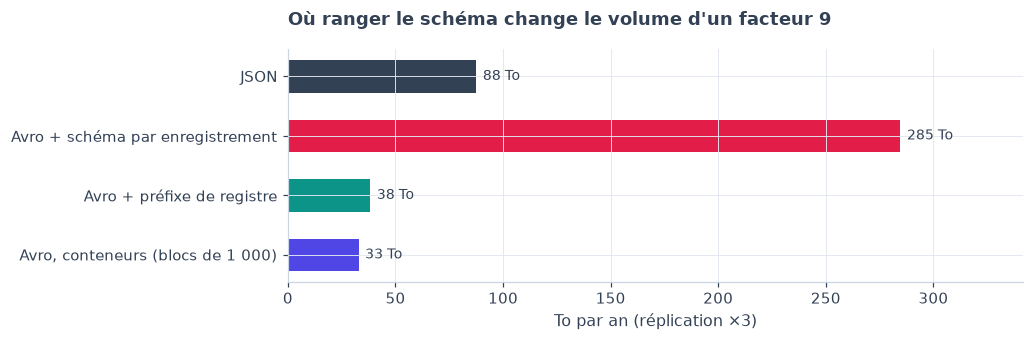

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 3.2))
ax.barh(vol.index, vol.values, color=[SLATE, ROSE, TEAL, INDIGO], height=0.55)
for i, v in enumerate(vol.values):
    ax.text(v + 3, i, f"{v:.0f} To", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, vol.max() * 1.2); ax.set_xlabel("To par an (réplication ×3)")
ax.set_title("Où ranger le schéma change le volume d'un facteur 9")
plt.tight_layout(); plt.show()

Les mesures confirment le seuil : environ 1 % de surcoût vers 67 enregistrements par bloc
(nos enregistrements synthétiques font 30 octets en moyenne). Le schéma par
enregistrement multiplierait le volume par 9 ; le préfixe de registre coûte 17 % ; les
conteneurs, presque rien.

> **À retenir.** Le schéma de l'écrivain doit être amorti : une fois par fichier (blocs
> de quelques centaines d'enregistrements suffisent), ou réduit à un identifiant de
> quelques octets par enregistrement.

## Exercice 4.9 : quels changements d'API sont sûrs ?

**Énoncé.** Une API JSON évolue. Pour chaque changement, dire s'il est sûr (a) si l'on met
à jour tous les serveurs avant les clients, (b) si l'on met à jour les clients d'abord,
(c) si des applications mobiles anciennes resteront en service indéfiniment. Les deux
côtés sont des **lecteurs tolérants** (ils ignorent les champs inconnus) mais exigent les
champs qu'ils déclarent obligatoires, avec le bon type.

1. ajouter un paramètre de requête facultatif ;
2. ajouter un paramètre de requête obligatoire ;
3. ajouter un champ de réponse ;
4. supprimer un champ de réponse que les clients lisent ;
5. renommer un paramètre de requête (sans alias) ;
6. passer un champ de réponse de nombre à chaîne.

**Rappels.** Serveurs d'abord : il faut la compatibilité descendante sur les requêtes et
ascendante sur les réponses ; clients d'abord : l'inverse ; clients jamais mis à jour :
l'ancien client doit fonctionner indéfiniment avec le nouveau serveur (cours 5, section 4).

**Solution.** On représente chaque contrat par ses champs (type, obligatoire ?) et on
vérifie les deux sens possibles : *ancien client -> nouveau serveur* (le seul croisement
qui se produit en (a) et en (c)) et *nouveau client -> ancien serveur* (le seul en (b),
puisque tous les clients sont à jour avant le premier serveur).

In [6]:
def valide(doc, schema):
    """Lecteur tolérant : champs obligatoires présents et bien typés ; inconnus ignorés."""
    for nom, (typ, oblig) in schema.items():
        if nom not in doc:
            if oblig:
                return False
        elif not isinstance(doc[nom], typ):
            return False
    return True

def exemple(schema):
    return {nom: {str: "x", int: 1}[typ] for nom, (typ, _) in schema.items()}

REQ = {"produit": (str, True)}
REP = {"prix": (int, True), "stock": (int, True)}
changements = {
    "1. paramètre facultatif ajouté": ({**REQ, "devise": (str, False)}, REP),
    "2. paramètre obligatoire ajouté": ({**REQ, "devise": (str, True)}, REP),
    "3. champ de réponse ajouté": (REQ, {**REP, "delai": (int, True)}),
    "4. champ de réponse supprimé": (REQ, {"prix": (int, True)}),
    "5. paramètre renommé": ({"article": (str, True)}, REP),
    "6. réponse : nombre -> chaîne": (REQ, {"prix": (str, True), "stock": (int, True)}),
}
rows = []
for nom, (req2, rep2) in changements.items():
    ancien_vers_nouveau = valide(exemple(REQ), req2) and valide(exemple(rep2), REP)
    nouveau_vers_ancien = valide(exemple(req2), REQ) and valide(exemple(REP), rep2)
    rows.append({"changement": nom, "(a) serveurs d'abord": ancien_vers_nouveau,
                 "(b) clients d'abord": nouveau_vers_ancien,
                 "(c) anciens clients pour toujours": ancien_vers_nouveau})
api = pd.DataFrame(rows).set_index("changement")
api.replace({True: "sûr", False: "cassé"})

,(a) serveurs d'abord,(b) clients d'abord,(c) anciens clients pour toujours
changement,,,
1. paramètre facultatif ajouté,sûr,sûr,sûr
2. paramètre obligatoire ajouté,cassé,sûr,cassé
3. champ de réponse ajouté,sûr,cassé,sûr
4. champ de réponse supprimé,cassé,sûr,cassé
5. paramètre renommé,cassé,cassé,cassé
6. réponse : nombre -> chaîne,cassé,cassé,cassé


Lecture. **Serveurs d'abord** : seuls (1) et (3) sont sûrs ; (2) casse parce que les
anciens clients n'envoient pas le paramètre devenu obligatoire, (4) et (6) parce que les
anciens clients ne trouvent plus, ou plus sous le bon type, un champ qu'ils exigent, (5)
parce que le nouveau serveur ne reconnaît plus l'ancien nom. **Clients d'abord** : le
tableau s'inverse en partie ; (2) et (4) deviennent sûrs (l'ancien serveur ignore le
paramètre en trop ; le nouveau client n'exige plus `stock`), mais (3) casse (le nouveau
client exige `delai`, que l'ancien serveur n'envoie pas), et (5), (6) restent cassés.
**Anciens clients pour toujours** : même verdict que (a), mais sans fin ; seuls les
changements additifs et facultatifs sont permis, sinon il faut ouvrir une nouvelle version
d'API.

> **À retenir.** Avec des lecteurs tolérants, les ajouts facultatifs sont sûrs ; toute
> exigence nouvelle, suppression, renommage ou changement de type casse les anciens
> clients. L'ordre « serveurs d'abord » réduit les cas à vérifier, mais pas pour des
> clients qu'on ne met jamais à jour.

## Exercice 4.10 : délais d'expiration, relances et doublons

**Énoncé.** Un service répond en un temps log-normal de médiane 2 ms ($\sigma = 0{,}8$) ;
0,5 % des réponses subissent en plus une retransmission de 200 ms. Les requêtes et les
réponses se perdent chacune avec probabilité $p = 0{,}2\,\%$.

1. Quel délai d'expiration $T$ choisir pour que moins de 0,1 % des appels réussis soient
   abandonnés à tort ?
2. Avec $T$ = 10 ms, quelle proportion d'appels expire ? Parmi eux, quelle proportion a
   pourtant été exécutée par le serveur ?
3. Avec jusqu'à 3 tentatives et sans idempotence, estimer la proportion d'actions
   exécutées deux fois. Comparer $T$ = 10 ms et $T$ = 250 ms.
4. Si le serveur ralentit et que la fraction $f$ des tentatives expire, quel est le
   facteur d'amplification de la charge avec 3 tentatives ?

**Rappels.** Un délai expiré ne dit pas si la requête a été traitée ; relancer sans
idempotence duplique les actions exécutées (cours 5, section 3).

**Solution.**

*1.* $T$ doit dépasser le quantile 99,9 % des temps de réponse. La queue à 200 ms concerne
0,5 % des réponses, plus que 0,1 % : il faut donc $T > 200$ ms environ (le corps
log-normal, lui, a son quantile 99,9 % vers $2\,e^{3{,}09 \times 0{,}8} \approx 24$ ms).

*2.* Avec $T$ = 10 ms : $P(\text{lognormal} > 10) = P(Z > \ln 5 / 0{,}8 \approx 2{,}01)
\approx 2{,}2\,\%$, plus les 0,5 % retransmis, plus les pertes ($\approx 0{,}4\,\%$) :
environ 3,1 % d'expirations. Toutes, sauf les requêtes perdues (0,2 %), ont été exécutées :
environ 94 % des appels expirés ont en réalité réussi côté serveur.

*3.* Chaque expiration d'un appel exécuté produit un doublon à la relance : environ
2,9 % des actions en double avec $T$ = 10 ms, contre environ 0,2 % avec $T$ = 250 ms (il ne
reste que les réponses perdues).

*4.* Les tentatives par appel valent $1 + f + f^2$ : 1,1 pour $f$ = 10 %, 1,75 pour
$f$ = 50 %, 3 si tout expire. La charge triple au moment où le serveur est déjà lent :
d'où les budgets de relances et le backoff exponentiel.

In [7]:
def simuler(T, n=200_000, p=0.002, essais=3, seed=1):
    g = np.random.default_rng(seed)
    execs = np.zeros(n, dtype=int)
    ok = np.zeros(n, dtype=bool)
    expire_1 = exec_1 = 0
    for k in range(essais):
        actifs = ~ok
        perdu_req = g.random(n) < p
        lat = 2 * np.exp(0.8 * g.standard_normal(n)) + (g.random(n) < 0.005) * 200
        perdu_rep = g.random(n) < p
        execute = actifs & ~perdu_req
        execs += execute
        reussi = execute & ~perdu_rep & (lat <= T)
        if k == 0:
            expire_1 = (actifs & ~reussi).mean()
            exec_1 = (execute & ~reussi).sum() / max((actifs & ~reussi).sum(), 1)
        ok |= reussi
    return {"T (ms)": T, "expirés à la 1re tentative": expire_1, "dont exécutés quand même": exec_1,
            "actions en double": (execs >= 2).mean(), "échec final": (~ok).mean()}

lat = 2 * np.exp(0.8 * rng.standard_normal(1_000_000)) + (rng.random(1_000_000) < 0.005) * 200
print(f"quantile 99,9 % des temps de réponse : {np.percentile(lat, 99.9):.0f} ms")
pd.DataFrame([simuler(10), simuler(250)]).set_index("T (ms)")

quantile 99,9 % des temps de réponse : 204 ms


,expirés à la 1re tentative,dont exécutés quand même,actions en double,échec final
T (ms),,,,
10,0.031,0.936,0.029,3.000e-05
250,0.004,0.514,0.002,0.000e+00


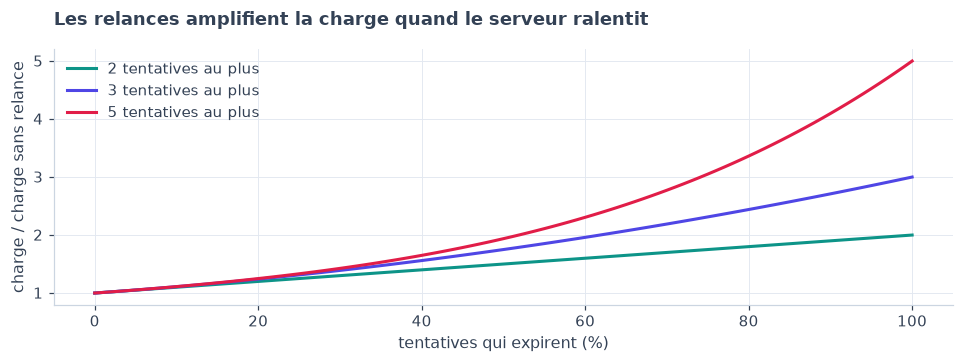

In [8]:
f = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(9, 3.4))
for k, c in [(2, TEAL), (3, INDIGO), (5, ROSE)]:
    ax.plot(f * 100, sum(f ** i for i in range(k)), color=c, label=f"{k} tentatives au plus")
ax.set_xlabel("tentatives qui expirent (%)"); ax.set_ylabel("charge / charge sans relance")
ax.set_title("Les relances amplifient la charge quand le serveur ralentit")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

La simulation confirme : avec $T$ = 10 ms, environ 3 % d'expirations dont la quasi-totalité
avaient été exécutées, et près de 3 % de doublons ; avec $T$ = 250 ms, les doublons tombent
à environ 0,2 % (réponses perdues), au prix d'appels qui attendent parfois 250 ms. Seule
l'idempotence supprime le dilemme.

> **À retenir.** Un délai d'expiration se règle sur la queue de la distribution des temps
> de réponse ; trop court, il transforme la latence en doublons ; et chaque relance
> ajoute de la charge au pire moment.